In [1]:
import os
import pandas as pd


def doc_csv(ten_tep):
    """Doc tep csv trong thu muc data/, neu khong co thi doc o thu muc hien tai."""
    duong_dan = os.path.join("data", ten_tep)
    if not os.path.exists(duong_dan):
        duong_dan = ten_tep
    return pd.read_csv(duong_dan)

## 2. Tự tính lan truyền tiến

In [2]:
# -*- coding: utf-8 -*-
"""Bước 1: tự tính lan truyền tiến bằng numpy.

Chú thích viết tiếng Việt có dấu, phần in ra màn hình viết không dấu.
"""

import numpy as np


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def relu(z):
    return np.maximum(0, z)


# Phần 1: một nơ-ron với hàm sigmoid, chính là hồi quy logistic
w = np.array([0.8, -0.5, 0.3])
b = -0.2
x = np.array([2.0, 1.0, 3.0])
z = w @ x + b
print("Mot no-ron:")
print(f" z = {w[0]}*{x[0]} + ({w[1]})*{x[1]} + {w[2]}*{x[2]}"
        f" + ({b}) = {z:.2f}")
print(f" a = sigmoid(z) = {sigmoid(z):.4f}")
print()

# Phần 2: mạng 2 đầu vào, 2 nơ-ron ẩn ReLU, 1 nơ-ron ra
# Trọng số tự đặt để mạng tính đúng phép XOR
W1 = np.array([[1.0, 1.0],       # cột 1: trọng số vào nơ-ron ẩn h1
                [1.0, 1.0]])      # cột 2: trọng số vào nơ-ron ẩn h2
b1 = np.array([0.0, -1.0])
W2 = np.array([1.0, -2.0])
b2 = 0.0

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
print("Mang giai XOR:")
print(" x1 x2     h1 h2     y")
for x in X:
    h = relu(x @ W1 + b1)          # lớp ẩn
    y = h @ W2 + b2                # lớp ra
    print(f" {x[0]:.0f}    {x[1]:.0f}    {h[0]:.0f}   {h[1]:.0f}"
        f"    {y:.0f}")
print()

# Cả bốn đầu vào cùng lúc bằng phép nhân ma trận
H = relu(X @ W1 + b1)
Y = H @ W2 + b2
print("Tinh ca bang mot lan:", Y)

Mot no-ron:
 z = 0.8*2.0 + (-0.5)*1.0 + 0.3*3.0 + (-0.2) = 1.80
 a = sigmoid(z) = 0.8581

Mang giai XOR:
 x1 x2     h1 h2     y
 0    0    0   0    0
 0    1    1   0    1
 1    0    1   0    1
 1    1    2   1    0

Tinh ca bang mot lan: [0. 1. 1. 0.]


## 3. Một nơ-ron và một lớp ẩn trên XOR

In [3]:
# -*- coding: utf-8 -*-
"""Bước 2: một nơ-ron không giải được XOR, một lớp ẩn thì được."""

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

df = doc_csv("xor.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = LogisticRegression().fit(X_tr, y_tr)
print(f"Hoi quy logistic: {accuracy_score(y_te, lr.predict(X_te)):.4f}")
print()

# Dữ liệu nhỏ nên dùng solver="lbfgs", học nhanh và ổn định hơn
print("So no-ron an   so tham so   tap hoc    tap kiem tra")
for so in [1, 2, 4, 8]:
    mlp = MLPClassifier(hidden_layer_sizes=(so,), solver="lbfgs",
                        max_iter=5000, random_state=0)
    mlp.fit(X_tr, y_tr)
    # coefs_ là danh sách ma trận trọng số, intercepts_ là hệ số chặn
    so_ts = sum(w.size for w in mlp.coefs_)
    so_ts += sum(b.size for b in mlp.intercepts_)
    a_hoc = accuracy_score(y_tr, mlp.predict(X_tr))
    a_kt = accuracy_score(y_te, mlp.predict(X_te))
    print(f"     {so:2d}           {so_ts:3d}        {a_hoc:.4f}"
        f"    {a_kt:.4f}")

Hoi quy logistic: 0.4500

So no-ron an   so tham so   tap hoc    tap kiem tra
      1             5        0.6533    0.6900
      2             9        0.6533    0.6900
      4            17        0.9033    0.9300
      8            33        0.9133    0.9100


## 4. Độ lớn mạng và điều chuẩn

In [4]:
# -*- coding: utf-8 -*-
"""Bước 3: mạng to thì học vẹt, điều chuẩn bằng alpha thì đỡ."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = doc_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def mang(lop_an, alpha):
    return make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=lop_an, alpha=alpha,
                        solver="lbfgs", max_iter=20000, random_state=0),
    )


print("Ba mang              tap hoc   tap kiem tra")
for ten, lop_an, alpha in [("(2,), alpha 1e-4", (2,), 1e-4),
                            ("(100, 100), 1e-5", (100, 100), 1e-5),
                            ("(100, 100), 1.0", (100, 100), 1.0)]:
    m = mang(lop_an, alpha).fit(X_tr, y_tr)
    print(f" {ten:18s} {accuracy_score(y_tr, m.predict(X_tr)):.4f}"
        f"    {accuracy_score(y_te, m.predict(X_te)):.4f}")
print()

# Chọn alpha bằng kiểm định chéo, chỉ trên tập học
print("alpha      kiem dinh cheo")
diem = {}
for alpha in [1e-5, 1e-3, 0.1, 1.0, 3.0, 10.0]:
    diem[alpha] = cross_val_score(mang((100, 100), alpha),
                                X_tr, y_tr, cv=5).mean()
    print(f" {alpha:<8} {diem[alpha]:.4f}")
a_tot = max(diem, key=diem.get)
m = mang((100, 100), a_tot).fit(X_tr, y_tr)
print(f"alpha tot nhat = {a_tot}, tap kiem tra "
        f"{accuracy_score(y_te, m.predict(X_te)):.4f}")

Ba mang              tap hoc   tap kiem tra
 (2,), alpha 1e-4   0.8444    0.8533


 (100, 100), 1e-5   1.0000    0.7867


 (100, 100), 1.0    0.8800    0.9067

alpha      kiem dinh cheo


 1e-05    0.7778


 0.001    0.7600


 0.1      0.7733


 1.0      0.8578


 3.0      0.8444


 10.0     0.8356


alpha tot nhat = 1.0, tap kiem tra 0.9067


## 5. Mạng nơ-ron khi quên chuẩn hoá

In [5]:
# -*- coding: utf-8 -*-
"""Bước 4: mạng nơ-ron khi quên chuẩn hoá."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = doc_csv("sinh_vien_mo_rong.csv")
X = df[["gio_on", "diem_giua_ky", "chi_tieu"]]
y = df["qua_mon"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

tho = MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000,
                    random_state=0).fit(X_tr, y_tr)
chuan = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000,
                    random_state=0),
).fit(X_tr, y_tr)

print(f"Doan bua ca lop qua : {y_te.mean():.4f}")
print(f"Khong chuan hoa     : "
        f"{accuracy_score(y_te, tho.predict(X_te)):.4f}")
print(f"Co chuan hoa        : "
        f"{accuracy_score(y_te, chuan.predict(X_te)):.4f}")
print()

# Mạng không chuẩn hoá đoán ra sao
du = tho.predict(X_te)
print("Khong chuan hoa, so ban doan qua:", du.sum(), "tren", len(du))

Doan bua ca lop qua : 0.6000
Khong chuan hoa     : 0.4000
Co chuan hoa        : 0.9000

Khong chuan hoa, so ban doan qua: 0 tren 30


## 6. Nhận dạng chữ số viết tay

In [6]:
# -*- coding: utf-8 -*-
"""Bước 5: nhận dạng chữ số viết tay bằng MLP."""

import numpy as np
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mang = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000,
                random_state=0),
).fit(X_tr, y_tr)
mlp = mang[-1]

print("Kich thuoc cac ma tran trong so:",
        [w.shape for w in mlp.coefs_])
so_ts = sum(w.size for w in mlp.coefs_)
so_ts += sum(b.size for b in mlp.intercepts_)
print("Tong so tham so:", so_ts)
print("So vong hoc:", mlp.n_iter_)
mm = mlp.loss_curve_
print(f"Mat mat vong 1: {mm[0]:.4f}, vong 10: {mm[9]:.4f},"
        f" vong cuoi: {mm[-1]:.4f}")
print()

du = mang.predict(X_te)
print(f"Accuracy tren tap kiem tra: {accuracy_score(y_te, du):.4f}")
sai = np.flatnonzero(du != y_te)
print("So anh doan sai:", len(sai), "tren", len(y_te))
for i in sai:
    print(f" anh {i:3d}: that la {y_te[i]}, doan la {du[i]}")
print()

# Dừng sớm: giữ riêng 10% tập học để theo dõi
dung_som = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000,
                early_stopping=True, random_state=0),
).fit(X_tr, y_tr)
print("Dung som sau", dung_som[-1].n_iter_, "vong, accuracy",
        f"{accuracy_score(y_te, dung_som.predict(X_te)):.4f}")
print()

# So với các mô hình đã học, cùng tập học và tập kiểm tra
khac = {
    "Logistic co chuan hoa": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN, k = 5": KNeighborsClassifier(),
    "SVM kernel RBF": SVC(),
}
for ten, mh in khac.items():
    acc = accuracy_score(y_te, mh.fit(X_tr, y_tr).predict(X_te))
    print(f"{ten:22s} {acc:.4f}")

Kich thuoc cac ma tran trong so: [(64, 100), (100, 10)]
Tong so tham so: 7510
So vong hoc: 144
Mat mat vong 1: 2.5206, vong 10: 0.4448, vong cuoi: 0.0052

Accuracy tren tap kiem tra: 0.9844
So anh doan sai: 7 tren 450
 anh   6: that la 9, doan la 3
 anh  61: that la 5, doan la 7
 anh  77: that la 2, doan la 1
 anh  85: that la 9, doan la 7
 anh 276: that la 8, doan la 2
 anh 428: that la 7, doan la 9
 anh 443: that la 4, doan la 7



Dung som sau 44 vong, accuracy 0.9578

Logistic co chuan hoa  0.9711
KNN, k = 5             0.9867
SVM kernel RBF         0.9911


# 7. Bài tập

In [7]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Bo XOR cua muc 3, chia 75/25 co phan tang
xor = doc_csv("xor.csv")
X_xor_tr, X_xor_te, y_xor_tr, y_xor_te = train_test_split(
    xor[["x1", "x2"]], xor["nhan"], test_size=0.25, random_state=17,
    stratify=xor["nhan"]
)

# Bo hai vang trang cua muc 4
trang = doc_csv("hai_vang_trang.csv")
X_trang_tr, X_trang_te, y_trang_tr, y_trang_te = train_test_split(
    trang[["x1", "x2"]], trang["nhan"], test_size=0.25, random_state=17,
    stratify=trang["nhan"]
)

# Bo chu so viet tay cua muc 6
X_chu, y_chu = load_digits(return_X_y=True)
X_chu_tr, X_chu_te, y_chu_tr, y_chu_te = train_test_split(
    X_chu, y_chu, test_size=0.25, random_state=17, stratify=y_chu
)
print("XOR:", X_xor_tr.shape, X_xor_te.shape,
      "| hai vang trang:", X_trang_tr.shape, X_trang_te.shape,
      "| chu so:", X_chu_tr.shape, X_chu_te.shape)

XOR: (300, 2) (100, 2) | hai vang trang: (225, 2) (75, 2) | chu so: (1347, 64) (450, 64)


## Bài tập 1: Tự dự đoán bằng trọng số đã học

In [8]:
mlp_xor = MLPClassifier(hidden_layer_sizes=(8,), solver="lbfgs",
                        max_iter=5000, random_state=0).fit(X_xor_tr, y_xor_tr)

W1, W2 = mlp_xor.coefs_              # W1: (2, 8), W2: (8, 1)
b1, b2 = mlp_xor.intercepts_         # b1: (8,),   b2: (1,)
print("Kich thuoc W1, b1, W2, b2:", W1.shape, b1.shape, W2.shape, b2.shape)
print("Ham kich hoat lop an:", mlp_xor.activation, "| lop ra:", mlp_xor.out_activation_)
print()


def relu(z):
    return np.maximum(0, z)


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


nam_diem = X_xor_te.to_numpy()[:5]

# Lan truyen tien: lop an roi lop ra
z_an = nam_diem @ W1 + b1            # tong co trong so cua 8 no-ron an
a_an = relu(z_an)                    # dau ra lop an
z_ra = a_an @ W2 + b2                # tong co trong so cua no-ron ra
xac_suat_tu_tinh = sigmoid(z_ra).ravel()

xac_suat_thu_vien = mlp_xor.predict_proba(X_xor_te.iloc[:5])[:, 1]

print("   x1        x2      tu tinh        thu vien       chenh lech   nhan that")
for diem, p_tu, p_tv, nhan in zip(nam_diem, xac_suat_tu_tinh,
                                  xac_suat_thu_vien, y_xor_te.to_numpy()[:5]):
    print(f" {diem[0]:7.4f}  {diem[1]:7.4f}   {p_tu:.10f}   {p_tv:.10f}   "
          f"{abs(p_tu - p_tv):.1e}      {nhan}")
print()
print("Chenh lech lon nhat:", f"{np.abs(xac_suat_tu_tinh - xac_suat_thu_vien).max():.1e}")
print("So no-ron an dang bat (a > 0) o tung diem:", (a_an > 0).sum(axis=1))

Kich thuoc W1, b1, W2, b2: (2, 8) (8,) (8, 1) (1,)
Ham kich hoat lop an: relu | lop ra: logistic

   x1        x2      tu tinh        thu vien       chenh lech   nhan that
  0.3319  -0.5595   0.0182787409   0.0182787409   0.0e+00      0
 -0.7016  -0.8251   0.9993888434   0.9993888434   0.0e+00      1
  0.5155  -0.0052   0.7880695065   0.7880695065   0.0e+00      0
 -0.6036   0.2726   0.1372934994   0.1372934994   0.0e+00      0
  0.2748   0.3515   0.9577033244   0.9577033244   0.0e+00      1

Chenh lech lon nhat: 0.0e+00
So no-ron an dang bat (a > 0) o tung diem: [5 4 5 3 5]


**Nhận xét:** Xác suất tự tính bằng numpy trùng với cột thứ hai của `mlp.predict_proba` ở cả 5 điểm, tới 10 chữ số thập phân (chênh lệch in ra là 0). Ví dụ điểm đầu tiên, cả hai cách đều cho 0.0182787409.
1. Lớp ẩn: z = x·W1 + b1, rồi a = max(0, z). Mỗi nơ-ron ẩn tính một tổng có trọng số của x1 và x2, sau đó ReLU giữ lại phần dương và cắt phần âm về 0.
2. Lớp ra: z = a·W2 + b2, rồi p = 1 / (1 + e^(−z)). Nơ-ron ra tính tổng có trọng số của 8 giá trị lớp ẩn, sau đó sigmoid ép kết quả vào khoảng 0 đến 1 để đọc như xác suất của lớp 1.

## Bài tập 2: Một mạng XOR khác

In [9]:
# Bon dau vao cua bang XOR
X_bang = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor_dung = np.array([0, 1, 1, 0])

# h1 = max(0, x1 - x2), h2 = max(0, x2 - x1), y = h1 + h2
W_an = np.array([[1.0, -1.0],        # trong so cua x1 vao h1, h2
                 [-1.0, 1.0]])       # trong so cua x2 vao h1, h2
b_an = np.array([0.0, 0.0])
w_ra = np.array([1.0, 1.0])
b_ra = 0.0

lop_an = np.maximum(0, X_bang @ W_an + b_an)
dau_ra = lop_an @ w_ra + b_ra

print(" x1  x2    x1-x2   x2-x1    h1   h2    y    XOR dung")
for x, h, y_tinh, y_dung in zip(X_bang, lop_an, dau_ra, y_xor_dung):
    print(f"  {x[0]:.0f}   {x[1]:.0f}     {x[0] - x[1]:+.0f}      {x[1] - x[0]:+.0f}      "
          f"{h[0]:.0f}    {h[1]:.0f}    {y_tinh:.0f}       {y_dung}")
print()
print("Mang tinh dung ca bon dong:", np.array_equal(dau_ra, y_xor_dung))
print("y co bang |x1 - x2| khong:", np.array_equal(dau_ra, np.abs(X_bang[:, 0] - X_bang[:, 1])))

 x1  x2    x1-x2   x2-x1    h1   h2    y    XOR dung
  0   0     +0      +0      0    0    0       0
  0   1     -1      +1      0    1    1       1
  1   0     +1      -1      1    0    1       1
  1   1     +0      +0      0    0    0       0

Mang tinh dung ca bon dong: True
y co bang |x1 - x2| khong: True


**Nhận xét:** Tính bằng numpy cho cả bốn đầu vào, mạng cho y = 0, 1, 1, 0, trùng với bảng XOR ở cả bốn dòng.

- h1 = max(0, x1 − x2) chỉ bật khi x1 lớn hơn x2, tức trường hợp (1, 0), khi đó h1 = 1.
- h2 = max(0, x2 − x1) chỉ bật khi x2 lớn hơn x1, tức trường hợp (0, 1), khi đó h2 = 1.
- Khi hai đầu vào bằng nhau, (0, 0) hoặc (1, 1), cả hai hiệu đều bằng 0 nên cả hai nơ-ron đều tắt.


## Bài tập 3: So các hàm kích hoạt

In [10]:
print("Ham kich hoat   tap hoc   tap kiem tra   so vong lap")
ket_qua_kich_hoat = {}
for ham in ["logistic", "tanh", "relu"]:
    mang = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(100, 100), alpha=1.0, activation=ham,
                      solver="lbfgs", max_iter=20000, random_state=0),
    )
    with warnings.catch_warnings(record=True) as ds_canh_bao:
        warnings.simplefilter("always")
        mang.fit(X_trang_tr, y_trang_tr)
    chua_hoi_tu = any(issubclass(c.category, ConvergenceWarning) for c in ds_canh_bao)
    a_hoc = accuracy_score(y_trang_tr, mang.predict(X_trang_tr))
    a_kt = accuracy_score(y_trang_te, mang.predict(X_trang_te))
    ket_qua_kich_hoat[ham] = (a_hoc, a_kt)
    print(f" {ham:10s}     {a_hoc:.4f}     {a_kt:.4f}        {mang[-1].n_iter_:5d}"
          f"{'   (chua hoi tu)' if chua_hoi_tu else ''}")
so_diem_kt = len(y_trang_te)
print(f"Tap kiem tra co {so_diem_kt} diem, moi diem ung voi {1 / so_diem_kt:.4f} accuracy")

Ham kich hoat   tap hoc   tap kiem tra   so vong lap


 logistic       0.8400     0.8533           64


 tanh           0.8711     0.9067          348


 relu           0.8800     0.9067         1069
Tap kiem tra co 75 diem, moi diem ung voi 0.0133 accuracy


**Nhận xét:**
Mức chênh giữa logistic và hai hàm kia là 0.0533, tức 4 điểm trên 75 điểm kiểm tra. Đây là khác biệt thấy được nhưng không lớn, và tập kiểm tra nhỏ nên mỗi điểm đã ứng với 0.0133. Vì vậy chỉ nên kết luận rằng ở đây logistic kém hơn một chút, còn tanh và relu thì không phân biệt được.

Một cách hiểu hợp lý cho logistic: với `alpha=1.0` (điều chuẩn mạnh, ép trọng số nhỏ), đầu ra của hàm logistic quanh 0 gần như phẳng và chỉ nằm trong khoảng 0 đến 1, nên mạng khó uốn đường biên, kết quả 0.8533 bằng đúng mạng nhỏ (2,) và hồi quy logistic ở các bài trước. Accuracy tập học thấp nhất (0.8400) và việc dừng rất sớm sau 64 vòng phù hợp với cách hiểu này, nhưng bài này chưa kiểm chứng riêng bằng cách đổi alpha cho từng hàm.


## Bài tập 4: Tốc độ học

toc do hoc   so vong   mat mat cuoi   accuracy kiem tra   ghi chu


  0.0001        582     0.018928        0.9889          


  0.001         144     0.005210        0.9844          
  0.01           38     0.001077        0.9778          


  0.1            30     0.069038        0.9533          

Mat mat sau 1, 10, 50 vong va mat mat nho nhat tung dat
  0.0001    2.7276   2.2407   0.9839   nho nhat 0.018928
  0.001     2.5206   0.4448   0.0411   nho nhat 0.005210
  0.01      1.3994   0.0095     -      nho nhat 0.001077
  0.1       1.3335   0.0931     -      nho nhat 0.002745


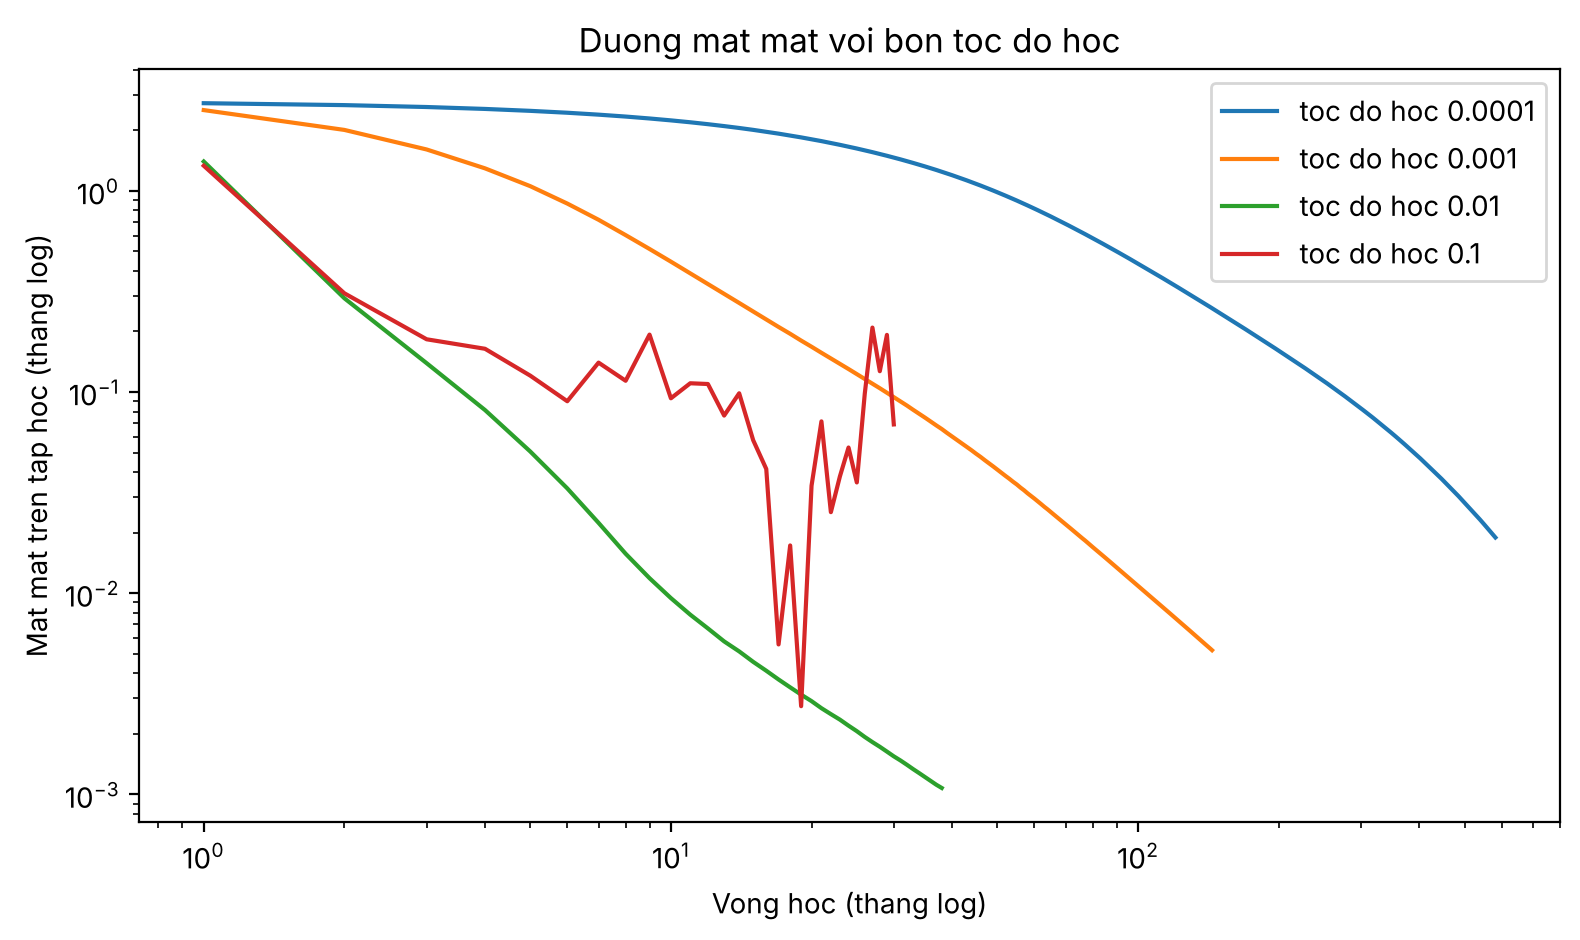

In [11]:
cac_toc_do = [0.0001, 0.001, 0.01, 0.1]
duong_mat_mat = {}
print("toc do hoc   so vong   mat mat cuoi   accuracy kiem tra   ghi chu")
for toc_do in cac_toc_do:
    mang = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(100,), learning_rate_init=toc_do,
                      max_iter=1000, random_state=0),
    )
    with warnings.catch_warnings(record=True) as ds_canh_bao:
        warnings.simplefilter("always")
        mang.fit(X_chu_tr, y_chu_tr)
    chua_hoi_tu = any(issubclass(c.category, ConvergenceWarning) for c in ds_canh_bao)
    mlp = mang[-1]
    duong_mat_mat[toc_do] = mlp.loss_curve_
    acc = accuracy_score(y_chu_te, mang.predict(X_chu_te))
    print(f"  {toc_do:<8}    {mlp.n_iter_:5d}     {mlp.loss_curve_[-1]:.6f}        {acc:.4f}"
          f"          {'chua hoi tu sau 1000 vong' if chua_hoi_tu else ''}")
print()

print("Mat mat sau 1, 10, 50 vong va mat mat nho nhat tung dat")
for toc_do, duong in duong_mat_mat.items():
    v50 = f"{duong[49]:.4f}" if len(duong) >= 50 else "  -   "
    print(f"  {toc_do:<8}  {duong[0]:.4f}   {duong[9]:.4f}   {v50}   nho nhat {min(duong):.6f}")

plt.figure(figsize=(8, 4.8))
for toc_do, duong in duong_mat_mat.items():
    plt.plot(range(1, len(duong) + 1), duong, label=f"toc do hoc {toc_do}")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Vong hoc (thang log)")
plt.ylabel("Mat mat tren tap hoc (thang log)")
plt.title("Duong mat mat voi bon toc do hoc")
plt.legend()
plt.tight_layout()
plt.savefig("toc_do_hoc.png", dpi=150)
plt.show()

**Nhận xét:**

**Tốc độ học quá nhỏ (0.0001)** làm mạng học rất chậm: mỗi bước chỉ sửa trọng số một chút, sau 10 vòng mất mát mới giảm từ 2.73 xuống 2.24, trong khi tốc độ 0.001 đã xuống 0.44. Mạng cần tới 582 vòng, gấp 4 lần mặc định, và dừng khi mất mát còn 0.0189, cao hơn các tốc độ 0.001 và 0.01. Ở đây nó vẫn kịp dừng trong giới hạn 1000 vòng, nhưng với dữ liệu lớn hơn thì dễ hết số vòng mà chưa học xong.

**Tốc độ học quá lớn (0.1)** làm việc học mất ổn định. Trên hình, đường màu đỏ không đi xuống đều mà giật lên xuống: mất mát có lúc chạm 0.0027 rồi lại vọt lên, và kết thúc ở 0.069, cao gấp 25 lần mức thấp nhất nó từng đạt. Bước đi quá dài khiến trọng số nhảy qua đáy của hàm mất mát sang phía bên kia. Mạng dừng sau 30 vòng không phải vì đã học xong mà vì mất mát không còn cải thiện đều, và accuracy kiểm tra thấp nhất, 0.9533.

Hai tốc độ ở giữa cho đường mất mát giảm trơn. Tốc độ 0.01 nhanh nhất (38 vòng) và đạt mất mát thấp nhất.

## Bài tập 5: Dò lưới cho mạng nơ-ron

In [12]:
luoi = {
    "mlpclassifier__hidden_layer_sizes": [(10,), (50,), (100,), (50, 50)],
    "mlpclassifier__alpha": [0.0001, 0.01, 1],
}
mo_hinh = make_pipeline(StandardScaler(),
                        MLPClassifier(max_iter=1000, random_state=0))
tim = GridSearchCV(mo_hinh, luoi, cv=5).fit(X_chu_tr, y_chu_tr)

bang = pd.DataFrame(tim.cv_results_["params"])
bang.columns = ["alpha", "lop_an"]
bang["diem"] = tim.cv_results_["mean_test_score"]
bang["lop_an"] = bang["lop_an"].astype(str)
print("Diem kiem dinh cheo, hang la lop an, cot la alpha")
print(bang.pivot(index="lop_an", columns="alpha", values="diem")
      .loc[["(10,)", "(50,)", "(100,)", "(50, 50)"]].round(4).to_string())
print()

acc_mlp = tim.score(X_chu_te, y_chu_te)
acc_svm = SVC().fit(X_chu_tr, y_chu_tr).score(X_chu_te, y_chu_te)
print("Cap tot nhat:", tim.best_params_)
print(f"Diem kiem dinh cheo cua cap tot nhat: {tim.best_score_:.4f}")
print(f"Accuracy tap kiem tra, MLP tot nhat : {acc_mlp:.4f} "
      f"(sai {round((1 - acc_mlp) * len(y_chu_te))} tren {len(y_chu_te)} anh)")
print(f"Accuracy tap kiem tra, SVM kernel RBF: {acc_svm:.4f} "
      f"(sai {round((1 - acc_svm) * len(y_chu_te))} tren {len(y_chu_te)} anh)")

Diem kiem dinh cheo, hang la lop an, cot la alpha
alpha     0.0001  0.0100  1.0000
lop_an                          
(10,)     0.9480  0.9488  0.9651
(50,)     0.9740  0.9755  0.9785
(100,)    0.9755  0.9755  0.9777
(50, 50)  0.9681  0.9681  0.9777

Cap tot nhat: {'mlpclassifier__alpha': 1, 'mlpclassifier__hidden_layer_sizes': (50,)}
Diem kiem dinh cheo cua cap tot nhat: 0.9785
Accuracy tap kiem tra, MLP tot nhat : 0.9822 (sai 8 tren 450 anh)
Accuracy tap kiem tra, SVM kernel RBF: 0.9911 (sai 4 tren 450 anh)


**Nhận xét:** Cặp tốt nhất là **`hidden_layer_sizes=(50,)` với `alpha=1`**, điểm kiểm định chéo 0.9785. Trên tập kiểm tra, mô hình này đạt **0.9822** (sai 8 trên 450 ảnh), **không vượt được SVM kernel RBF** (0.9911, sai 4 ảnh).

Đọc bảng điểm kiểm định chéo:

- **Theo độ lớn mạng:** mạng 10 nơ-ron thấp hơn hẳn (0.948 đến 0.965), tức là quá nhỏ cho 10 chữ số. Từ 50 nơ-ron trở lên thì điểm gần như đứng yên quanh 0.974 đến 0.979. Thêm nơ-ron hay thêm lớp ẩn không giúp gì thêm, mạng (50, 50) còn thấp hơn (50,) khi alpha nhỏ (0.9681 so với 0.9740).
- **Theo alpha:** ở mọi kích thước mạng, alpha = 1 cho điểm cao nhất. Lợi ích rõ nhất ở mạng nhỏ nhất và mạng hai lớp (10 nơ-ron: từ 0.9480 lên 0.9651; (50, 50): từ 0.9681 lên 0.9777). Điều chuẩn mạnh hơn giúp mạng bớt khớp nhiễu của tập học.


## Bài tập 6: Mạng nơ-ron cho hồi quy

Mang hoc 999 vong
MAE tren tap kiem tra (ty dong)
 Mang no-ron : 0.5008
 Duong thang : 0.2578

Du doan (ty dong)
 dien tich   mang no-ron   duong thang   chenh
     60 m2       5.05          5.12     -0.07
    100 m2       8.24          8.24     -0.00
    150 m2      14.69         12.13     +2.56
    250 m2      28.18         19.91     +8.26

Dien tich trong tap hoc: tu 37.6 toi 117.5 m2
Do doc tu 200 toi 250 m2: mang 0.1364, duong thang 0.0778


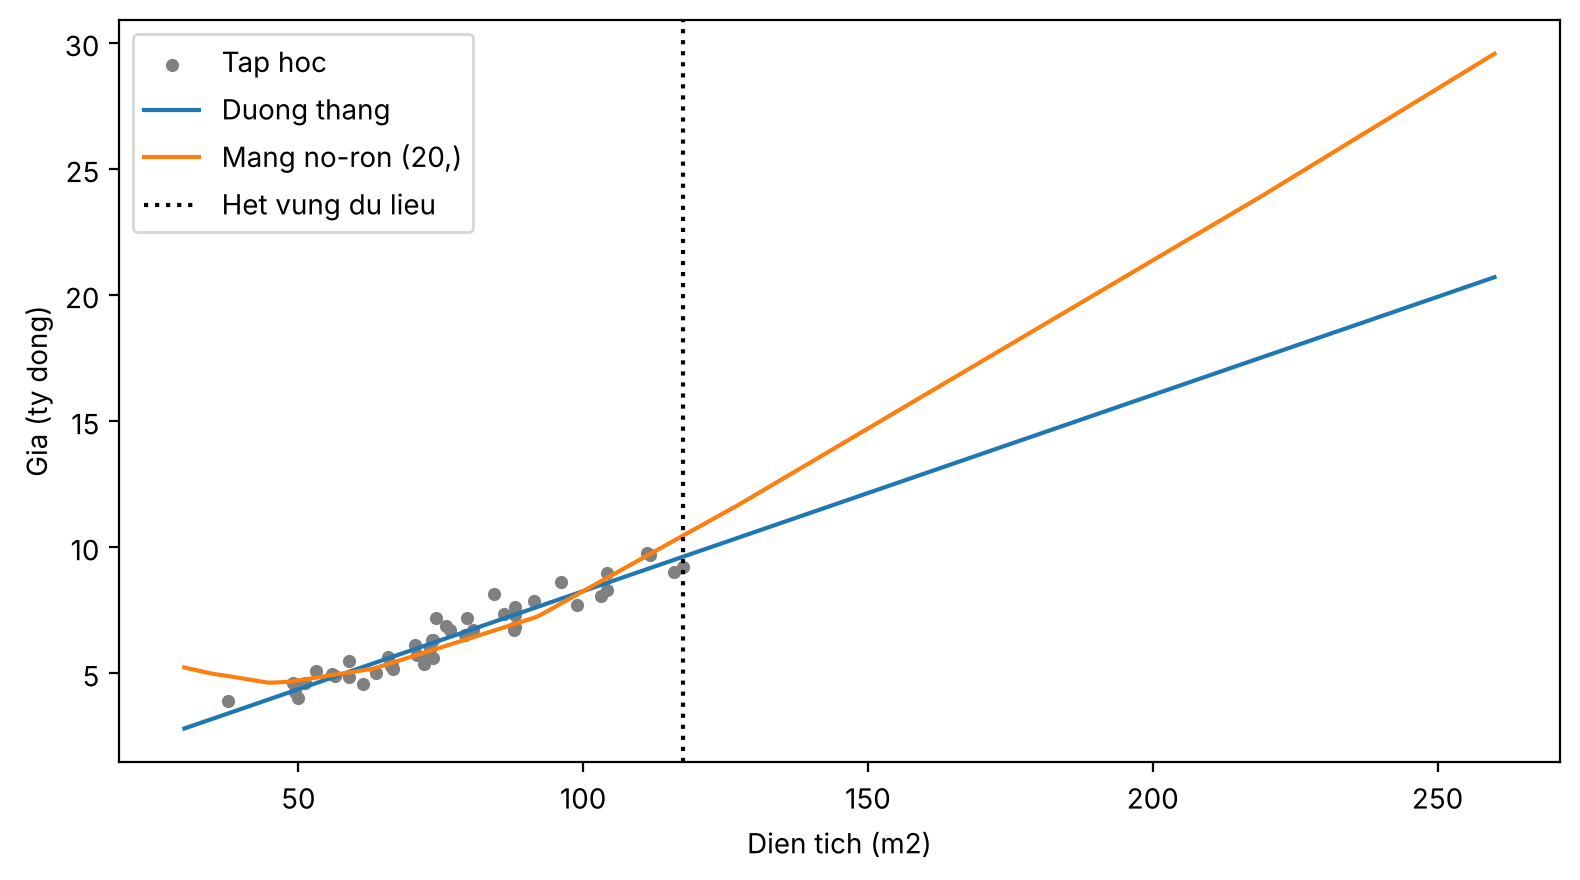

In [13]:
gia_nha = doc_csv("gia_nha.csv")
X_gia = gia_nha[["dien_tich"]]
y_gia = gia_nha["gia"]
X_gia_tr, X_gia_te, y_gia_tr, y_gia_te = train_test_split(
    X_gia, y_gia, test_size=0.2, random_state=42
)

mang_hoi_quy = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(20,), max_iter=5000, random_state=0),
).fit(X_gia_tr, y_gia_tr)
duong_thang = LinearRegression().fit(X_gia_tr, y_gia_tr)

print(f"Mang hoc {mang_hoi_quy[-1].n_iter_} vong")
print("MAE tren tap kiem tra (ty dong)")
print(f" Mang no-ron : {mean_absolute_error(y_gia_te, mang_hoi_quy.predict(X_gia_te)):.4f}")
print(f" Duong thang : {mean_absolute_error(y_gia_te, duong_thang.predict(X_gia_te)):.4f}")
print()

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan (ty dong)")
print(" dien tich   mang no-ron   duong thang   chenh")
for dien_tich, gia_mang, gia_duong in zip(can_moi["dien_tich"],
                                          mang_hoi_quy.predict(can_moi),
                                          duong_thang.predict(can_moi)):
    print(f" {dien_tich:6.0f} m2     {gia_mang:6.2f}        {gia_duong:6.2f}     {gia_mang - gia_duong:+.2f}")
print()
print(f"Dien tich trong tap hoc: tu {X_gia_tr['dien_tich'].min()} toi "
      f"{X_gia_tr['dien_tich'].max()} m2")

# Do doc cua hai duong o vung ngoai suy (ty dong moi m2)
doc_mang = (mang_hoi_quy.predict(pd.DataFrame({"dien_tich": [250.0]}))[0]
            - mang_hoi_quy.predict(pd.DataFrame({"dien_tich": [200.0]}))[0]) / 50
print(f"Do doc tu 200 toi 250 m2: mang {doc_mang:.4f}, duong thang {duong_thang.coef_[0]:.4f}")

luoi_dien_tich = pd.DataFrame({"dien_tich": np.linspace(30, 260, 300)})
plt.figure(figsize=(8, 4.5))
plt.scatter(X_gia_tr, y_gia_tr, s=14, color="gray", label="Tap hoc")
plt.plot(luoi_dien_tich, duong_thang.predict(luoi_dien_tich), label="Duong thang")
plt.plot(luoi_dien_tich, mang_hoi_quy.predict(luoi_dien_tich), label="Mang no-ron (20,)")
plt.axvline(X_gia_tr["dien_tich"].max(), color="k", linestyle=":", label="Het vung du lieu")
plt.xlabel("Dien tich (m2)")
plt.ylabel("Gia (ty dong)")
plt.legend()
plt.tight_layout()
plt.show()

**Nhận xét:** Trên tập kiểm tra, MAE của mạng nơ-ron là **0.5008 tỷ**, gần gấp đôi hồi quy tuyến tính (**0.2578 tỷ**). Mạng học 999 vòng.

Trong vùng có dữ liệu (tập học từ 37.6 tới 117.5 m²), hai mô hình gần như trùng nhau: căn 60 m² chênh 0.07 tỷ, căn 100 m² không chênh. Ra ngoài vùng đó thì chúng tách xa dần: căn 250 m² được mạng đoán **28.18 tỷ**, cao hơn đường thẳng 8.26 tỷ.

Không có căn 250 m² nào trong dữ liệu để biết giá thật, nên không thể nói 28.18 hay 19.91 đúng hơn. Điều nói được là: dữ liệu trong vùng đã học gần như thẳng, đường thẳng kéo dài đúng xu hướng đó bằng 2 tham số, còn mạng có 61 tham số cho 48 căn nên dễ uốn theo nhiễu, và phần ngoại suy của nó phụ thuộc vào những chi tiết ngẫu nhiên như `random_state`.
